In [19]:
# ==============================================================================
# ENVIRONMENT SETUP & DATA INGESTION
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
import seaborn as sns

# Ensure inline plotting in notebook cells
%matplotlib inline

# Global typography standards (Rubric >= 14pt)
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.size': 14,
    'axes.titlesize': 17.5,
    'axes.labelsize': 15.5,
    'xtick.labelsize': 14.0,
    'ytick.labelsize': 14.0,
    'legend.fontsize': 14.0,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.2,
    'figure.autolayout': False
})

# Load the verified 100,000 population dataset (6 original variables)
df = pd.read_csv('digital_habits_vs_mental_health.csv')
print(f"Dataset successfully loaded: {df.shape[0]:,} rows × {df.shape[1]} columns.")

Dataset successfully loaded: 100,000 rows × 6 columns.


In [20]:
# ==============================================================================
# FOUR-PILLAR DATA QUALITY & INTEGRITY AUDIT
# ==============================================================================
def execute_four_pillar_audit(data):
    print("=" * 65)
    print("      FOUR-PILLAR DATA QUALITY & INTEGRITY AUDIT REPORT")
    print("=" * 65)

    # Pillar 1: Completeness
    null_count = data.isnull().sum().sum()
    numeric_data = data.select_dtypes(include=[np.number])
    sentinel_check = (numeric_data < 0).sum().sum()
    print(f"Pillar 1 (Completeness): {null_count} explicit nulls across {len(data.columns)} columns.")
    print(f"  -> Hidden Missingness: {sentinel_check} negative sentinel values found.")

    # Pillar 2: Validity
    v_screen = data['screen_time_hours'].between(0, 24).all()
    v_tiktok = data['hours_on_TikTok'].between(0, 24).all()
    v_sleep = data['sleep_hours'].between(0, 24).all()
    v_stress = data['stress_level'].between(1, 10).all()
    v_mood = data['mood_score'].between(1, 10).all()
    v_platforms = data['social_media_platforms_used'].between(1, 5).all()
    print(f"Pillar 2 (Validity): All domains valid = "
          f"{v_screen and v_tiktok and v_sleep and v_stress and v_mood and v_platforms}.")

    # Pillar 3: Consistency
    viol_tiktok = (data['hours_on_TikTok'] > data['screen_time_hours']).sum()
    viol_day = ((data['screen_time_hours'] + data['sleep_hours']) > 24.0).sum()
    print(f"Pillar 3 (Consistency):")
    print(f"  -> Rule A (TikTok <= Screen Time): {viol_tiktok} logical violations.")
    print(f"  -> Rule B (Screen Time + Sleep <= 24h): {viol_day} logical violations.")

    # Pillar 4: Uniqueness
    dup_rows = data.duplicated().sum()
    print(f"Pillar 4 (Uniqueness): {dup_rows:,} repeated value patterns identified across {len(data):,} records.")
    print("=" * 65)

execute_four_pillar_audit(df)

      FOUR-PILLAR DATA QUALITY & INTEGRITY AUDIT REPORT
Pillar 1 (Completeness): 0 explicit nulls across 6 columns.
  -> Hidden Missingness: 0 negative sentinel values found.
Pillar 2 (Validity): All domains valid = True.
Pillar 3 (Consistency):
  -> Rule A (TikTok <= Screen Time): 0 logical violations.
  -> Rule B (Screen Time + Sleep <= 24h): 0 logical violations.
Pillar 4 (Uniqueness): 1,865 repeated value patterns identified across 100,000 records.


In [21]:
# ==============================================================================
# FEATURE ENGINEERING & STRATIFIED SUMMARY STATISTICS
# ==============================================================================
df['stress_tier'] = pd.cut(
    df['stress_level'],
    bins=[0, 4, 7, 10],
    labels=['Low (1–4)', 'Moderate (5–7)', 'High (8–10)']
)
df['sleep_category'] = pd.cut(
    df['sleep_hours'],
    bins=[0, 5.9, 7.9, 12.0],
    labels=['Short Sleep (<6h)', 'Normal Sleep (6-8h)', 'Optimal Sleep (>8h)']
)
df['screen_time_bin'] = pd.cut(
    df['screen_time_hours'],
    bins=np.arange(1, 13, 1),
    include_lowest=True,
    labels=[f"{i}-{i+1}h" for i in range(1, 12)]
)
df['non_tiktok_screen_hours'] = df['screen_time_hours'] - df['hours_on_TikTok']
df['net_balance'] = df['sleep_hours'] - df['screen_time_hours']

tier_order = ['Low (1–4)', 'Moderate (5–7)', 'High (8–10)']

summary_table = df.groupby('stress_tier', observed=False).agg(
    Sample_Size=('stress_level', 'count'),
    Screen_Mean=('screen_time_hours', 'mean'),
    Screen_SD=('screen_time_hours', 'std'),
    Screen_Median=('screen_time_hours', 'median'),
    Screen_IQR=('screen_time_hours', lambda x: np.percentile(x, 75) - np.percentile(x, 25)),
    TikTok_Mean=('hours_on_TikTok', 'mean'),
    TikTok_SD=('hours_on_TikTok', 'std'),
    TikTok_Median=('hours_on_TikTok', 'median'),
    TikTok_IQR=('hours_on_TikTok', lambda x: np.percentile(x, 75) - np.percentile(x, 25)),
    Sleep_Mean=('sleep_hours', 'mean'),
    Sleep_SD=('sleep_hours', 'std'),
    Sleep_Median=('sleep_hours', 'median'),
    Sleep_IQR=('sleep_hours', lambda x: np.percentile(x, 75) - np.percentile(x, 25)),
    Mood_Mean=('mood_score', 'mean'),
    Mood_SD=('mood_score', 'std'),
    Mood_Median=('mood_score', 'median'),
    Mood_IQR=('mood_score', lambda x: np.percentile(x, 75) - np.percentile(x, 25))
).reindex(tier_order)

summary_table.to_csv('table1_summary_statistics.csv')
summary_table.round(2)

,Sample_Size,Screen_Mean,Screen_SD,Screen_Median,Screen_IQR,TikTok_Mean,TikTok_SD,TikTok_Median,TikTok_IQR,Sleep_Mean,Sleep_SD,Sleep_Median,Sleep_IQR,Mood_Mean,Mood_SD,Mood_Median,Mood_IQR
stress_tier,,,,,,,,,,,,,,,,,
Low (1–4),21212,4.65,1.74,4.6,2.4,1.73,0.80,1.6,1.1,8.39,1.05,8.4,1.5,9.92,0.33,10.0,0.0
Moderate (5–7),51909,5.92,1.78,5.9,2.4,2.33,0.95,2.2,1.3,7.08,1.14,7.1,1.5,9.34,0.93,10.0,1.0
High (8–10),26879,7.23,1.79,7.2,2.5,3.08,1.12,3.0,1.6,5.71,1.18,5.7,1.6,7.84,1.44,8.0,2.0


In [22]:
# ==============================================================================
# STATISTICAL HYPOTHESIS TESTING & CORRELATION AUDIT
# ==============================================================================
# 1. Hypothesis Testing: One-Way ANOVA across Stress Tiers
low_sleep = df[df['stress_tier'] == 'Low (1–4)']['sleep_hours']
mod_sleep = df[df['stress_tier'] == 'Moderate (5–7)']['sleep_hours']
high_sleep = df[df['stress_tier'] == 'High (8–10)']['sleep_hours']

f_stat_sleep, p_val_sleep = stats.f_oneway(low_sleep, mod_sleep, high_sleep)
kw_stat_sleep, kw_p_val = stats.kruskal(low_sleep, mod_sleep, high_sleep)

print("=" * 65)
print("      STATISTICAL HYPOTHESIS TESTING REPORT")
print("=" * 65)
print(f"One-Way ANOVA (Sleep across Stress Tiers):")
print(f"  -> F-Statistic = {f_stat_sleep:.2f}, p-value = {p_val_sleep:.3e}")
print(f"Kruskal-Wallis Test (Non-parametric verification):")
print(f"  -> H-Statistic = {kw_stat_sleep:.2f}, p-value = {kw_p_val:.3e}")
print("  => Result: Reject H0 (p < 0.001). Cross-tier sleep differences are statistically significant.")
print("-" * 65)

# 2. Decomposing the TikTok Slope (Total vs. Non-TikTok Screen Time)
slope_tot, int_tot, r_tot, p_tot, _ = stats.linregress(df['hours_on_TikTok'], df['screen_time_hours'])
slope_nt, int_nt, r_nt, p_nt, _ = stats.linregress(df['hours_on_TikTok'], df['non_tiktok_screen_hours'])
print(f"OLS Regression (TikTok vs Total Screen Time):     slope = {slope_tot:.2f}h, R² = {r_tot**2:.3f}, p = {p_tot:.3e}")
print(f"OLS Regression (TikTok vs Non-TikTok Screen):     slope = {slope_nt:.2f}h, R² = {r_nt**2:.3f}, p = {p_nt:.3e}")
print("-" * 65)

# 3. Multivariate Correlation Matrix
corr_matrix = df[['screen_time_hours', 'hours_on_TikTok', 'sleep_hours',
                  'stress_level', 'mood_score', 'social_media_platforms_used']].corr()

print("Multivariate Pearson Correlation Matrix:")
print(corr_matrix.round(3).to_string())
print("=" * 65)

      STATISTICAL HYPOTHESIS TESTING REPORT
One-Way ANOVA (Sleep across Stress Tiers):
  -> F-Statistic = 33281.96, p-value = 0.000e+00
Kruskal-Wallis Test (Non-parametric verification):
  -> H-Statistic = 39701.00, p-value = 0.000e+00
  => Result: Reject H0 (p < 0.001). Cross-tier sleep differences are statistically significant.
-----------------------------------------------------------------
OLS Regression (TikTok vs Total Screen Time):     slope = 1.36h, R² = 0.543, p = 0.000e+00
OLS Regression (TikTok vs Non-TikTok Screen):     slope = 0.36h, R² = 0.076, p = 0.000e+00
-----------------------------------------------------------------
Multivariate Pearson Correlation Matrix:
                             screen_time_hours  hours_on_TikTok  sleep_hours  stress_level  mood_score  social_media_platforms_used
screen_time_hours                        1.000            0.737        0.000         0.494      -0.343                        0.004
hours_on_TikTok                          0.737   

In [23]:
# ==============================================================================
# GENERATE TABLE 1 – DESCRIPTIVE STATISTICS (REPORT SECTION 2)
# ==============================================================================
columns = [
    "screen_time_hours",
    "hours_on_TikTok",
    "sleep_hours",
    "stress_level",
    "social_media_platforms_used",
    "mood_score"
]

table1 = df[columns].agg(
    ["count", "mean", "std", "median", "min", "max"]
).T

table1.columns = ["N", "Mean", "SD", "Median", "Min", "Max"]
table1["N"] = table1["N"].astype(int)

print(table1.round(2))

                                  N  Mean    SD  Median  Min   Max
screen_time_hours            100000  6.00  1.99     6.0  1.0  12.0
hours_on_TikTok              100000  2.40  1.08     2.3  0.2   7.2
sleep_hours                  100000  6.99  1.47     7.0  3.0  10.0
stress_level                 100000  6.18  2.05     6.0  1.0  10.0
social_media_platforms_used  100000  3.00  1.41     3.0  1.0   5.0
mood_score                   100000  9.06  1.28    10.0  2.0  10.0


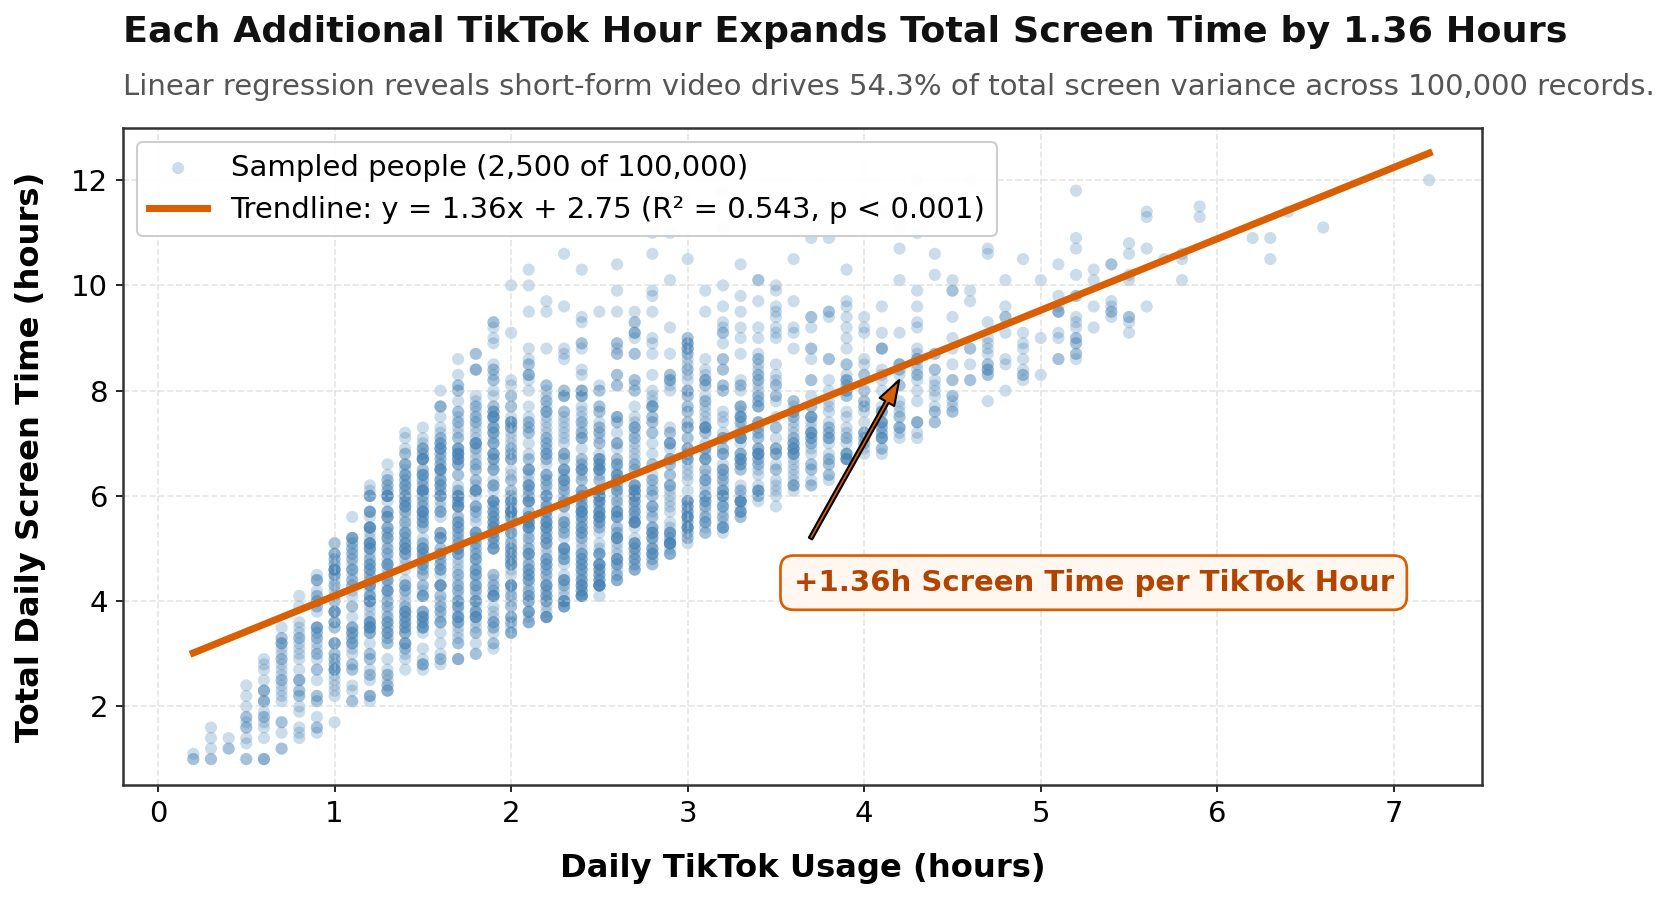

In [24]:
# ==============================================================================
# FIGURE 1 - OLS REGRESSION (TIKTOK VS TOTAL SCREEN TIME)
# ==============================================================================
slope, intercept, r_val, p_val, std_err = stats.linregress(df['hours_on_TikTok'], df['screen_time_hours'])
sample_df = df.sample(n=2500, random_state=42)

fig1, ax1 = plt.subplots(figsize=(11.5, 6.8), dpi=150)

ax1.scatter(sample_df['hours_on_TikTok'], sample_df['screen_time_hours'],
            color='#4682b4', alpha=0.28, s=34, edgecolors='none',
            label='Sampled people (2,500 of 100,000)')

x_vals = np.linspace(df['hours_on_TikTok'].min(), df['hours_on_TikTok'].max(), 200)
ax1.plot(x_vals, slope * x_vals + intercept, color='#d95f02', lw=3.4,
         label=f'Trendline: y = {slope:.2f}x + {intercept:.2f} (R² = {r_val**2:.3f}, p < 0.001)')

ax1.annotate('+1.36h Screen Time per TikTok Hour',
             xy=(4.25, slope * 4.25 + intercept), xytext=(3.6, 4.2),
             arrowprops=dict(facecolor='#d95f02', shrink=0.08, width=1.8, headwidth=8),
             fontsize=14.0, fontweight='bold', color='#b24400',
             bbox=dict(boxstyle='round,pad=0.45', fc='#fff7f0', ec='#d95f02', lw=1.3))

ax1.text(0.0, 1.13, "Each Additional TikTok Hour Expands Total Screen Time by 1.36 Hours",
         transform=ax1.transAxes, fontsize=17.5, fontweight='bold', color='#111111', ha='left')
ax1.text(0.0, 1.05, "Linear regression reveals short-form video drives 54.3% of total screen variance across 100,000 records.",
         transform=ax1.transAxes, fontsize=14.0, color='#555555', ha='left')

ax1.set_xlabel("Daily TikTok Usage (hours)", labelpad=12, fontweight='bold')
ax1.set_ylabel("Total Daily Screen Time (hours)", labelpad=12, fontweight='bold')
ax1.set_xlim(-0.2, 7.5)
ax1.set_ylim(0.5, 13.0)
ax1.grid(True, linestyle='--', alpha=0.5, color='#cccccc')
ax1.legend(loc='upper left', frameon=True, facecolor='white', edgecolor='#cccccc', framealpha=0.95)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("figure1_presentation_ready.png", dpi=300)
plt.show()

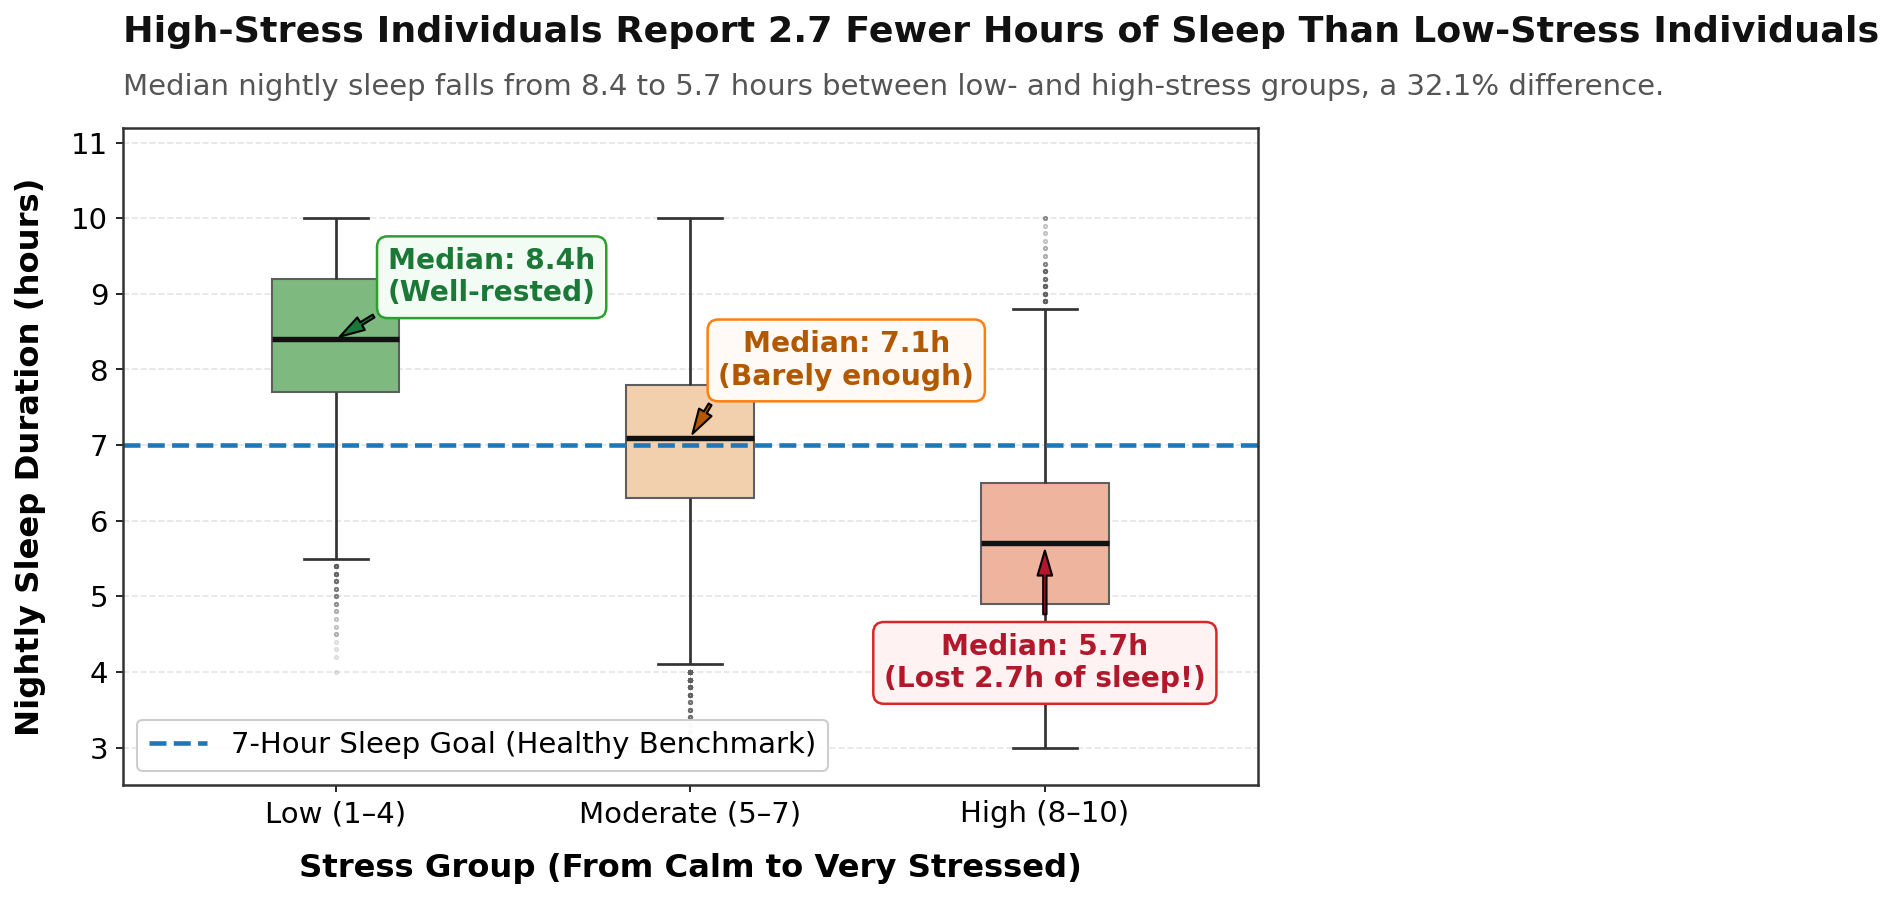

In [25]:
# ==============================================================================
# FIGURE 2 - CATEGORICAL BOXPLOT (STRESS VS SLEEP DURATION)
# ==============================================================================
fig2, ax2 = plt.subplots(figsize=(11.5, 6.8), dpi=150)

tier_palette = ['#74c476', '#fdd0a2', '#fcae91']
sns.boxplot(data=df, x='stress_tier', y='sleep_hours', hue='stress_tier',
            palette=tier_palette, width=0.36, legend=False,
            medianprops=dict(color='#111111', linewidth=2.6),
            whiskerprops=dict(color='#333333', linewidth=1.3),
            capprops=dict(color='#333333', linewidth=1.3),
            fliersize=1.5, flierprops=dict(marker='o', alpha=0.2), ax=ax2)

ax2.axhline(7.0, color='#1f77b4', linestyle='--', lw=2.2, label='7-Hour Sleep Goal (Healthy Benchmark)')

ax2.annotate('Median: 8.4h\n(Well-rested)',
             xy=(0.0, 8.4), xytext=(0.44, 8.9),
             arrowprops=dict(facecolor='#1b7837', shrink=0.08, width=1.6, headwidth=7),
             fontsize=13.5, fontweight='bold', color='#1b7837', ha='center',
             bbox=dict(boxstyle='round,pad=0.38', fc='#f2fbf4', ec='#2ca02c', lw=1.2))

ax2.annotate('Median: 7.1h\n(Barely enough)',
             xy=(1.0, 7.1), xytext=(1.44, 7.8),
             arrowprops=dict(facecolor='#b25900', shrink=0.08, width=1.6, headwidth=7),
             fontsize=13.5, fontweight='bold', color='#b25900', ha='center',
             bbox=dict(boxstyle='round,pad=0.38', fc='#fffaf5', ec='#ff7f0e', lw=1.2))

ax2.annotate('Median: 5.7h\n(Lost 2.7h of sleep!)',
             xy=(2.0, 5.7), xytext=(2.0, 3.8),
             arrowprops=dict(facecolor='#b2182b', shrink=0.08, width=1.6, headwidth=7),
             fontsize=13.5, fontweight='bold', color='#b2182b', ha='center',
             bbox=dict(boxstyle='round,pad=0.38', fc='#fff2f2', ec='#d62728', lw=1.2))

ax2.text(0.0, 1.13, "High-Stress Individuals Report 2.7 Fewer Hours of Sleep Than Low-Stress Individuals",
         transform=ax2.transAxes, fontsize=17.5, fontweight='bold', color='#111111', ha='left')
ax2.text(0.0, 1.05, "Median nightly sleep falls from 8.4 to 5.7 hours between low- and high-stress groups, a 32.1% difference.",
         transform=ax2.transAxes, fontsize=14.0, color='#555555', ha='left')

ax2.set_xlabel("Stress Group (From Calm to Very Stressed)", labelpad=12, fontweight='bold')
ax2.set_ylabel("Nightly Sleep Duration (hours)", labelpad=12, fontweight='bold')
ax2.set_ylim(2.5, 11.2)
ax2.set_xlim(-0.6, 2.6)
ax2.grid(axis='y', linestyle='--', alpha=0.5, color='#cccccc')
ax2.legend(loc='lower left', frameon=True, facecolor='white', edgecolor='#cccccc', framealpha=0.95)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("figure2_presentation_ready.png", dpi=300)
plt.show()

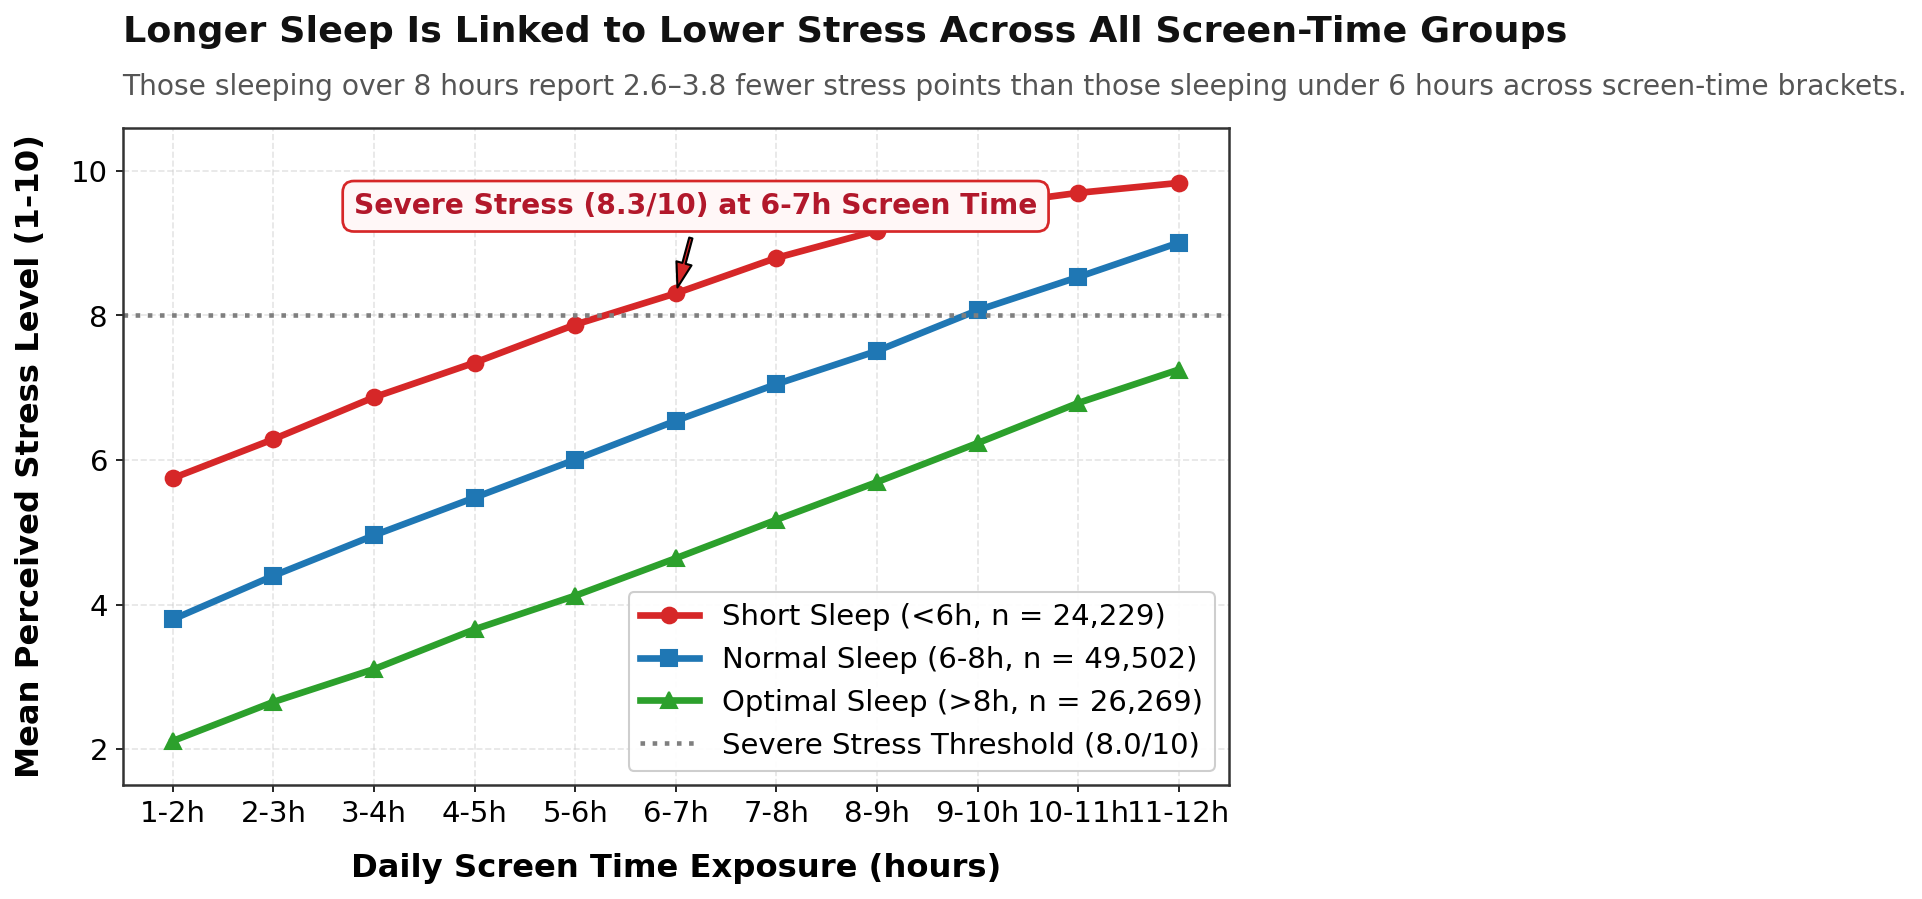

In [26]:
# ==============================================================================
# FIGURE 3 - INTERACTION PLOT (SCREEN X SLEEP X STRESS)
# ==============================================================================
interaction = df.groupby(['screen_time_bin', 'sleep_category'], observed=False)['stress_level'].mean().unstack()

fig3, ax3 = plt.subplots(figsize=(11.5, 6.8), dpi=150)
x_idx = np.arange(len(interaction.index))
bin_labels = interaction.index.astype(str)

ax3.plot(x_idx, interaction['Short Sleep (<6h)'], color='#d62728', lw=3.2, marker='o', markersize=7.5,
         label=f"Short Sleep (<6h, n = {(df['sleep_category']=='Short Sleep (<6h)').sum():,})")
ax3.plot(x_idx, interaction['Normal Sleep (6-8h)'], color='#1f77b4', lw=3.2, marker='s', markersize=7.5,
         label=f"Normal Sleep (6-8h, n = {(df['sleep_category']=='Normal Sleep (6-8h)').sum():,})")
ax3.plot(x_idx, interaction['Optimal Sleep (>8h)'], color='#2ca02c', lw=3.2, marker='^', markersize=7.5,
         label=f"Optimal Sleep (>8h, n = {(df['sleep_category']=='Optimal Sleep (>8h)').sum():,})")

ax3.axhline(8.0, color='#7f7f7f', linestyle=':', lw=2.2, label='Severe Stress Threshold (8.0/10)')

ax3.annotate('Severe Stress (8.3/10) at 6-7h Screen Time',
             xy=(5, interaction['Short Sleep (<6h)'].iloc[5]), xytext=(1.8, 9.4),
             arrowprops=dict(facecolor='#d62728', shrink=0.08, width=1.6, headwidth=7.5),
             fontsize=13.5, fontweight='bold', color='#b2182b',
             bbox=dict(boxstyle='round,pad=0.4', fc='#fff7f7', ec='#d62728', lw=1.3))

ax3.text(0.0, 1.13, "Longer Sleep Is Linked to Lower Stress Across All Screen-Time Groups",
         transform=ax3.transAxes, fontsize=17.5, fontweight='bold', color='#111111', ha='left')
ax3.text(0.0, 1.05, "Those sleeping over 8 hours report 2.6–3.8 fewer stress points than those sleeping under 6 hours across screen-time brackets.",
         transform=ax3.transAxes, fontsize=13.5, color='#555555', ha='left')

ax3.set_xlabel("Daily Screen Time Exposure (hours)", labelpad=12, fontweight='bold')
ax3.set_ylabel("Mean Perceived Stress Level (1-10)", labelpad=12, fontweight='bold')
ax3.set_xticks(x_idx)
ax3.set_xticklabels(bin_labels)
ax3.set_ylim(1.5, 10.6)
ax3.grid(True, linestyle='--', alpha=0.5, color='#cccccc')
ax3.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#cccccc', framealpha=0.95)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("figure3_presentation_ready.png", dpi=300)
plt.show()

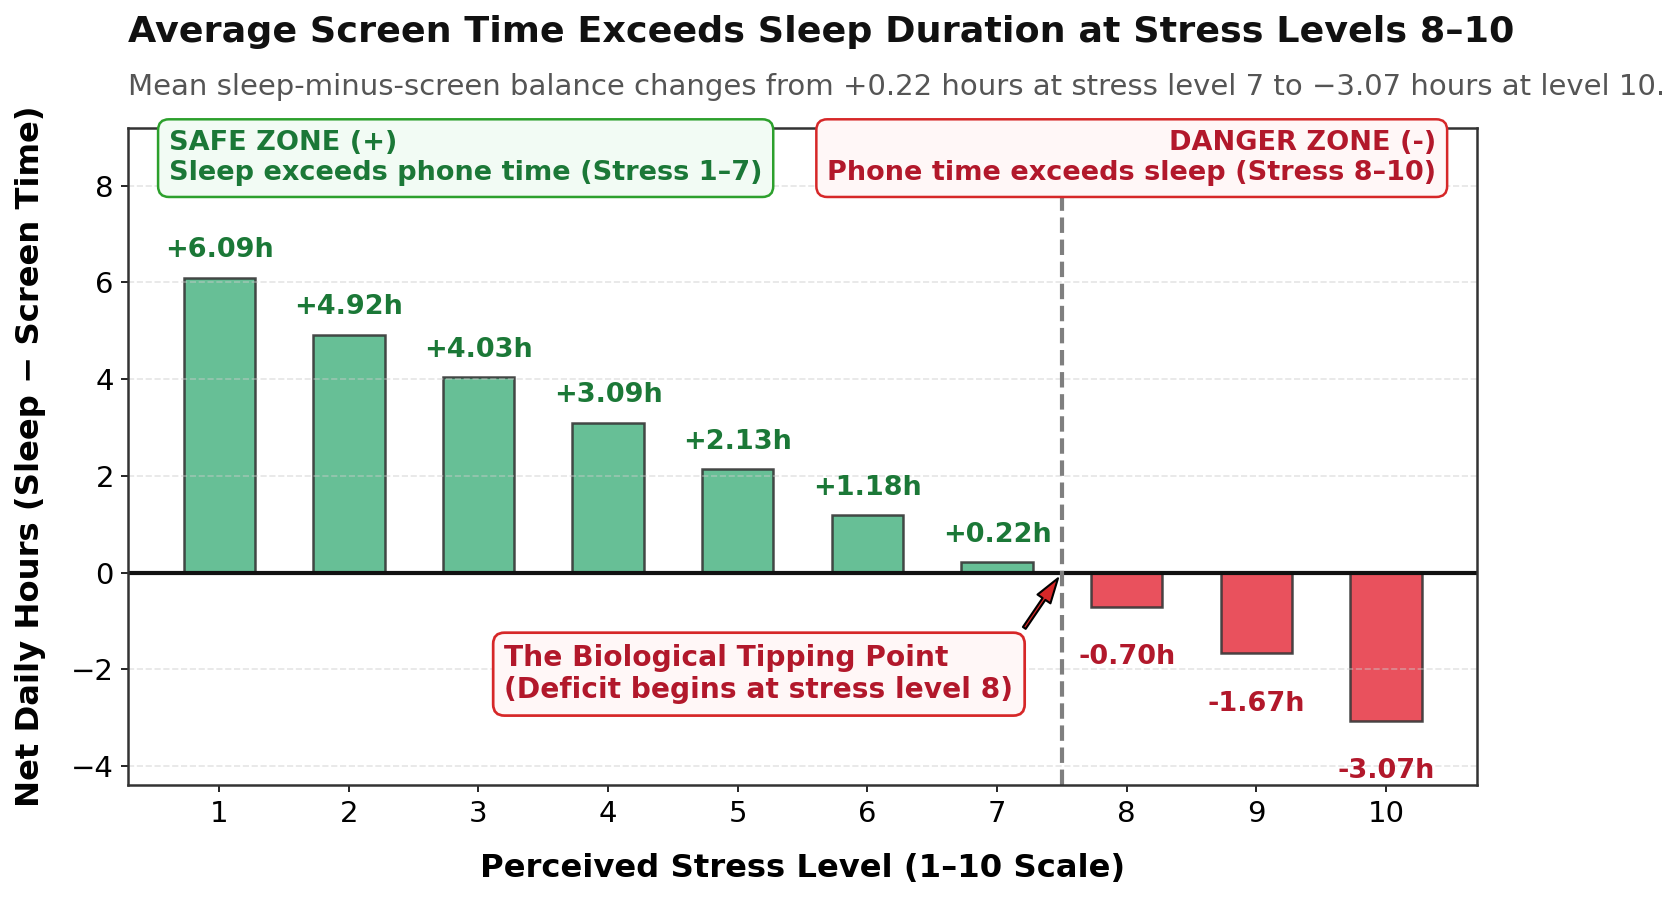

In [27]:
# ==============================================================================
# FIGURE 4 - DIVERGING BAR CHART (NET BIOLOGICAL BALANCE)
# ==============================================================================
balance = df.groupby('stress_level', observed=False)['net_balance'].mean()

fig4, ax4 = plt.subplots(figsize=(11.5, 6.8), dpi=150)
x = balance.index
y = balance.values

colors = ['#52b788' if v >= 0 else '#e63946' for v in y]
bars = ax4.bar(x, y, color=colors, width=0.55, edgecolor='#333333', lw=1.2, alpha=0.88)
ax4.axhline(0, color='#111111', lw=2.0)

for bar in bars:
    h = bar.get_height()
    offset = 7 if h >= 0 else -18
    color = '#1b7837' if h >= 0 else '#b2182b'
    prefix = '+' if h >= 0 else ''
    ax4.annotate(f"{prefix}{h:.2f}h",
                 xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, offset), textcoords="offset points",
                 ha='center', va='bottom' if h >= 0 else 'top',
                 fontsize=13.0, fontweight='bold', color=color)

ax4.axvline(7.5, color='#7f7f7f', linestyle='--', lw=2.0)
ax4.annotate('The Biological Tipping Point\n(Deficit begins at stress level 8)',
             xy=(7.5, 0), xytext=(3.2, -2.6),
             arrowprops=dict(facecolor='#d62728', shrink=0.08, width=1.6, headwidth=7.5),
             fontsize=13.5, fontweight='bold', color='#b2182b',
             bbox=dict(boxstyle='round,pad=0.4', fc='#fff7f7', ec='#d62728', lw=1.3))

ax4.text(0.03, 0.92, 'SAFE ZONE (+)\nSleep exceeds phone time (Stress 1–7)',
         transform=ax4.transAxes, fontsize=13.0, fontweight='bold', color='#1b7837',
         bbox=dict(boxstyle='round,pad=0.4', fc='#f2fbf4', ec='#2ca02c', lw=1.2))
ax4.text(0.97, 0.92, 'DANGER ZONE (-)\nPhone time exceeds sleep (Stress 8–10)',
         transform=ax4.transAxes, fontsize=13.0, fontweight='bold', color='#b2182b', ha='right',
         bbox=dict(boxstyle='round,pad=0.4', fc='#fff7f7', ec='#d62728', lw=1.2))

ax4.text(0.0, 1.13, "Average Screen Time Exceeds Sleep Duration at Stress Levels 8–10",
         transform=ax4.transAxes, fontsize=17.5, fontweight='bold', color='#111111', ha='left')
ax4.text(0.0, 1.05, "Mean sleep-minus-screen balance changes from +0.22 hours at stress level 7 to −3.07 hours at level 10.",
         transform=ax4.transAxes, fontsize=14.0, color='#555555', ha='left')

ax4.set_xlabel("Perceived Stress Level (1–10 Scale)", labelpad=12, fontweight='bold')
ax4.set_ylabel("Net Daily Hours (Sleep − Screen Time)", labelpad=12, fontweight='bold')
ax4.set_xticks(range(1, 11))
ax4.set_xlim(0.3, 10.7)
ax4.set_ylim(-4.4, 9.2)
ax4.grid(axis='y', linestyle='--', alpha=0.5, color='#cccccc')

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("figure4_presentation_ready.png", dpi=300)
plt.show()